# NIH ChestX-ray14 — 14-label Multi-label Training (L4)
ใช้ภาพหนึ่งภาพทำนายโรคได้หลาย label พร้อมกัน (multi-label) ไม่บังคับให้แต่ละภาพมีโรคเดียว
ป้าย `No Finding` แทนเวกเตอร์โรคทั้ง 14 ค่าเป็นศูนย์ ไม่ใช่ output class ที่ 15

Notebook นี้แยกจาก `Chest_Xray_Improved_L4.ipynb` เพื่อไม่รบกวน notebook/runtime ที่กำลังดาวน์โหลดข้อมูล
ข้อมูลเต็มมี 112,120 ภาพ; ใช้ official test list และแยก train/validation ตามผู้ป่วย
ทุกผลเป็นการทดลองเพื่อการศึกษา ไม่ใช่ระบบวินิจฉัยหรือการคัดกรองทางคลินิก

ต้องมีโค้ด `src/multilabel.py` จาก commit นี้ใน GitHub หรือ upload ไฟล์โค้ดเข้ารันไทม์ก่อนใช้
ถ้า runtime ปัจจุบันกำลังดาวน์โหลดอยู่ ให้ปล่อย cell นั้นทำงานจนเสร็จและอย่ารัน cell download ซ้ำ
เปลี่ยนไป notebook นี้หลังจากบันทึก path ของ dataset ที่โหลดเสร็จแล้ว

## 1. เตรียมโค้ดและไลบรารี
เปิด notebook จาก GitHub หรือ upload ไฟล์นี้ได้ โค้ดจะ clone repository เมื่อยังไม่มี `src/`
หากต้องการใช้ commit เดิมให้ใส่ CODE_REF เป็น commit SHA ที่บันทึกไว้
คง torch/torchvision ที่ Colab จัดมาเป็นคู่ไว้ ไม่ติดตั้ง CUDA ทับโดยไม่จำเป็น

In [19]:
from pathlib import Path
import subprocess, sys, os
REPO = "https://github.com/baconkak/Chest-X-Ray-Pneumonia-COVID-19-Screening.git"
CODE_REF = "main"  # Replace with the saved commit SHA to reproduce this code version.
project = Path("/content/chest-xray-improved")
if not project.exists():
    subprocess.run(["git", "clone", REPO, str(project)], check=True)
os.chdir(project)
subprocess.run(["git", "fetch", "origin", CODE_REF], check=True)
subprocess.run(["git", "checkout", "--detach", "FETCH_HEAD"], check=True)
sys.path.insert(0, str(project))
# A reused runtime may have imported src from the older notebook already.
for module in list(sys.modules):
    if module == "src" or module.startswith("src."):
        del sys.modules[module]
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "scikit-learn>=1.5,<2", "pandas>=2.2,<4", "matplotlib>=3.8,<4",
                "Pillow>=10.4,<13", "kagglehub>=0.3,<1", "tqdm>=4.66,<5"], check=True)
import torch
from src.engine import environment
CODE_SHA = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
print(environment())
print("Code commit:", CODE_SHA)
# Embedded multi-label helpers: this notebook does not need src/multilabel.py uploaded.
"""Patient-disjoint, 14-label NIH ChestX-ray14 training helpers.
Each image may have several findings. The model therefore emits one sigmoid
score per disease (multi-label), while ``No Finding`` is represented by an
all-zero disease target vector rather than a fifteenth output.
"""
from pathlib import Path
from dataclasses import dataclass, asdict
import hashlib
import json
import random
import time
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from torch import nn
from torch.utils.data import DataLoader, Dataset
from src.data import read_metadata, make_splits, transforms, _seed_worker
from src.engine import atomic_save, save_json
from src.models import build_model, configure_stage, TRANSFER_MODELS
DISEASE_LABELS = (
    'Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion',
    'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'Nodule',
    'Pleural_Thickening', 'Pneumonia', 'Pneumothorax',
)
TARGET_COLUMNS = tuple(f'target_{label}' for label in DISEASE_LABELS)
@dataclass
class MultiLabelConfig:
    seed: int = 42
    epochs: int = 20
    head_epochs: int = 2
    batch_size: int = 64
    image_size: int = 224
    lr: float = 1e-4
    finetune_lr: float = 1e-5
    weight_decay: float = 1e-4
    patience: int = 5
    min_delta: float = 1e-4
    pretrained: bool = True
    amp: bool = True
    amp_init_scale: float = 1024.
    num_workers: int = 4
def read_multilabel_metadata(root, allow_partial=False):
    """Read NIH metadata and create a stable 14-column multi-hot target."""
    frame, audit = read_metadata(root, allow_partial=allow_partial)
    tokens = frame['Finding Labels'].map(lambda value: set(value.split('|')))
    for label, column in zip(DISEASE_LABELS, TARGET_COLUMNS):
        frame[column] = tokens.map(lambda values: int(label in values)).astype('uint8')
    # Existing split helper stratifies patients by a single binary field. This
    # field means any disease is present; the actual model targets are columns.
    frame['target'] = frame[list(TARGET_COLUMNS)].max(axis=1).astype('uint8')
    audit['target'] = '14 independent disease labels; No Finding is all-zero'
    audit['target_labels'] = list(DISEASE_LABELS)
    audit['no_finding_images'] = int((frame[list(TARGET_COLUMNS)].sum(axis=1) == 0).sum())
    return frame, audit
def make_multilabel_splits(frame, root, mode='official', seed=42, max_patients=None):
    """Reuse the project's patient-grouped split checks for multi-label rows."""
    splits = make_splits(frame, root, mode=mode, seed=seed, max_patients=max_patients)
    for split_name, part in splits.items():
        support = part[list(TARGET_COLUMNS)].sum(axis=0)
        missing = [DISEASE_LABELS[i] for i, value in enumerate(support) if value == 0]
        if missing:
            raise ValueError(f'{split_name} has no positive examples for labels: {missing}')
    return splits
def multilabel_summary(splits):
    """Return image/patient and per-class supports for each partition."""
    summary = {}
    for name, frame in splits.items():
        positive = frame[list(TARGET_COLUMNS)].sum(axis=0).astype(int)
        summary[name] = {
            'images': int(len(frame)),
            'patients': int(frame.patient_id.nunique()),
            'no_finding_images': int((frame[list(TARGET_COLUMNS)].sum(axis=1) == 0).sum()),
            'labels': {
                label: {'positive_images': int(positive[column]),
                        'prevalence': float(positive[column] / len(frame))}
                for label, column in zip(DISEASE_LABELS, TARGET_COLUMNS)
            },
        }
    return summary
def save_multilabel_splits(splits, out):
    """Save deterministic manifests and a hash covering all targets."""
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    digest = hashlib.sha256()
    for name, frame in splits.items():
        manifest = frame.drop(columns=['path']).sort_values('Image Index')
        payload = manifest.to_csv(index=False, lineterminator='\n')
        digest.update(name.encode())
        digest.update(payload.encode())
        manifest.to_csv(out / f'{name}.csv', index=False)
    return digest.hexdigest(), multilabel_summary(splits)
class MultiLabelChestDataset(Dataset):
    def __init__(self, frame, train=False, size=224):
        self.frame = frame.reset_index(drop=True)
        self.paths = self.frame.path.tolist()
        self.targets = self.frame[list(TARGET_COLUMNS)].to_numpy(dtype=np.float32)
        self.transform = transforms(train, size)
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        from PIL import Image
        with Image.open(self.paths[index]) as image:
            x = self.transform(image.convert('RGB'))
        return x, torch.from_numpy(self.targets[index])
def make_multilabel_loaders(splits, batch_size=64, seed=42, size=224, num_workers=4):
    if num_workers < 0:
        raise ValueError('num_workers must be nonnegative')
    generator = torch.Generator().manual_seed(seed)
    loaders = {
        name: DataLoader(
            MultiLabelChestDataset(frame, train=(name == 'train'), size=size),
            batch_size=batch_size, shuffle=(name == 'train'), num_workers=num_workers,
            worker_init_fn=_seed_worker, persistent_workers=False,
            multiprocessing_context='spawn' if num_workers else None,
            pin_memory=torch.cuda.is_available(),
            generator=generator if name == 'train' else None,
        ) for name, frame in splits.items()
    }
    return loaders, generator
def _multilabel_model(name, n_labels, pretrained=True):
    model = build_model(name, pretrained=pretrained)
    head = model.classifier if name == 'densenet121' else model.fc
    linear = head[-1]
    if not isinstance(linear, nn.Linear):
        raise TypeError(f'Expected a Linear classifier for {name}')
    head[-1] = nn.Linear(linear.in_features, n_labels)
    return model
@torch.no_grad()
def predict_multilabel(model, loader, device):
    model.eval()
    labels, scores = [], []
    for x, y in loader:
        logits = model(x.to(device, non_blocking=True))
        if logits.shape != y.shape or not torch.isfinite(logits).all():
            raise RuntimeError('Invalid multi-label model output')
        labels.append(y.numpy())
        scores.append(logits.sigmoid().cpu().numpy())
    if not labels:
        raise ValueError('Empty evaluation loader')
    return np.concatenate(labels), np.concatenate(scores)
def multilabel_metrics(y_true, scores, thresholds=None):
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    if y_true.shape != scores.shape or y_true.ndim != 2 or y_true.shape[1] != len(DISEASE_LABELS):
        raise ValueError('Expected matching [images, 14 labels] arrays')
    if not np.isfinite(scores).all():
        raise ValueError('Scores contain non-finite values')
    thresholds = np.full(len(DISEASE_LABELS), .5) if thresholds is None else np.asarray(thresholds)
    pred = scores >= thresholds[None, :]
    per_class = {}
    aps, aucs = [], []
    for i, label in enumerate(DISEASE_LABELS):
        positives = int(y_true[:, i].sum())
        negatives = int(len(y_true) - positives)
        ap = float(average_precision_score(y_true[:, i], scores[:, i])) if positives else None
        auc = float(roc_auc_score(y_true[:, i], scores[:, i])) if positives and negatives else None
        if ap is not None:
            aps.append(ap)
        if auc is not None:
            aucs.append(auc)
        tp = int(((pred[:, i]) & (y_true[:, i] == 1)).sum())
        fp = int(((pred[:, i]) & (y_true[:, i] == 0)).sum())
        fn = int(((~pred[:, i]) & (y_true[:, i] == 1)).sum())
        tn = int(((~pred[:, i]) & (y_true[:, i] == 0)).sum())
        ratio = lambda numerator, denominator: float(numerator / denominator) if denominator else None
        per_class[label] = {
            'positive_images': positives, 'prevalence': float(positives / len(y_true)),
            'threshold': float(thresholds[i]), 'ap': ap, 'auroc': auc,
            'precision': ratio(tp, tp + fp), 'recall': ratio(tp, tp + fn),
            'specificity': ratio(tn, tn + fp), 'f1': ratio(2 * tp, 2 * tp + fp + fn),
        }
    return {
        'n_images': int(len(y_true)),
        'macro_ap': float(np.mean(aps)) if aps else None,
        'micro_ap': float(average_precision_score(y_true, scores, average='micro')),
        'macro_auroc': float(np.mean(aucs)) if aucs else None,
        'per_class': per_class,
    }
def select_multilabel_thresholds(y_true, scores, target_recall=.90):
    """Choose one validation-only threshold per disease at a declared recall."""
    thresholds = []
    for i, label in enumerate(DISEASE_LABELS):
        y, score = y_true[:, i], scores[:, i]
        if len(np.unique(y)) != 2:
            raise ValueError(f'Validation needs positive and negative samples for {label}')
        precision, recall, candidates = precision_recall_curve(y, score)
        valid = np.flatnonzero(recall[:-1] >= target_recall)
        if not len(valid):
            thresholds.append(0.0)
        else:
            best = max(valid, key=lambda j: (precision[j], candidates[j]))
            thresholds.append(float(candidates[best]))
    return np.asarray(thresholds, dtype=np.float32)
def train_multilabel_model(name, splits, config, split_hash, out_dir,
                           pos_weight_cap=10., target_recall=.90, resume=False):
    """Train one pretrained backbone with per-label capped positive weights."""
    if name not in TRANSFER_MODELS:
        raise ValueError(f'Multi-label transfer model not supported: {name}')
    if config.epochs < 2 or not 1 <= config.head_epochs < config.epochs:
        raise ValueError('Need at least 2 epochs and 1 <= head_epochs < epochs')
    if not np.isfinite(pos_weight_cap) or pos_weight_cap < 1:
        raise ValueError('pos_weight_cap must be finite and at least 1')
    out = Path(out_dir) / name
    out.mkdir(parents=True, exist_ok=True)
    best_path, last_path = out / 'best.pt', out / 'last.pt'
    if not resume and (best_path.exists() or last_path.exists()):
        raise FileExistsError(f'{out} already has checkpoints; use RESUME=True or a new RUN_NAME')
    if resume and not last_path.exists():
        raise FileNotFoundError(f'Cannot resume; missing checkpoint: {last_path}')
    seed = config.seed
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    amp = bool(config.amp and device.type == 'cuda')
    loaders, generator = make_multilabel_loaders(splits, config.batch_size, seed,
                                                 config.image_size, config.num_workers)
    train_y = splits['train'][list(TARGET_COLUMNS)].to_numpy(dtype=np.float32)
    positives = train_y.sum(axis=0)
    negatives = len(train_y) - positives
    if np.any(positives == 0) or np.any(negatives == 0):
        raise ValueError('Train split must contain positive and negative examples for every label')
    weights = np.clip(negatives / positives, 1., pos_weight_cap).astype(np.float32)
    run_config = {**asdict(config), 'pos_weight_cap': float(pos_weight_cap),
                  'target_recall': float(target_recall), 'labels': list(DISEASE_LABELS)}
    model = _multilabel_model(name, len(DISEASE_LABELS), pretrained=bool(config.pretrained)).to(device)
    train_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weights, device=device))
    val_loss = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=amp, init_scale=config.amp_init_scale)
    optimizer = scheduler = None
    best_ap, waiting, history = -float('inf'), 0, []
    state = None
    start_epoch = 0
    if resume:
        state = torch.load(last_path, map_location='cpu', weights_only=False)
        if state.get('split_hash') != split_hash or state.get('config') != run_config:
            raise ValueError('Resume config/split mismatch; use the original settings or a new RUN_NAME')
        model.load_state_dict(state['model'])
        start_epoch = state['epoch'] + 1
        best_ap, waiting, history = state['best_macro_ap'], state['waiting'], state['history']
        random.setstate(state['python_rng']); np.random.set_state(state['numpy_rng'])
        torch.set_rng_state(state['torch_rng'])
        if device.type == 'cuda' and state['cuda_rng'] is not None:
            torch.cuda.set_rng_state_all(state['cuda_rng'])
        generator.set_state(state['loader_rng'])
    for epoch in range(start_epoch, config.epochs):
        stage = 'head' if epoch < config.head_epochs else 'finetune'
        if optimizer is None or stage != history[-1]['stage']:
            configure_stage(model, name, stage)
            lr = config.lr if stage == 'head' else config.finetune_lr
            optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                          lr=lr, weight_decay=config.weight_decay)
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer, mode='max', patience=1, factor=.5)
            if state is not None:
                if state['stage'] == stage:
                    optimizer.load_state_dict(state['optimizer'])
                    scheduler.load_state_dict(state['scheduler'])
                    scaler.load_state_dict(state['scaler'])
                state = None
        model.train()
        if name in TRANSFER_MODELS:
            for module in model.modules():
                if isinstance(module, nn.BatchNorm2d):
                    module.eval()
        train_total, train_n = 0., 0
        for x, y in loaders['train']:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=amp):
                logits = model(x)
                if logits.shape != y.shape:
                    raise ValueError(f'Logits {logits.shape} != target {y.shape}')
                loss = train_loss(logits, y)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite training loss')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            grad_norm = nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], 5.,
                error_if_nonfinite=not amp)
            if not torch.isfinite(grad_norm) and not amp:
                raise RuntimeError('Non-finite gradient in full precision')
            scaler.step(optimizer); scaler.update()
            train_total += float(loss.detach()) * len(y); train_n += len(y)
        model.eval()
        val_total, val_n = 0., 0
        with torch.no_grad():
            for x, y in loaders['val']:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                with torch.autocast(device_type=device.type, enabled=amp):
                    logits = model(x)
                    loss = val_loss(logits, y)
                val_total += float(loss) * len(y); val_n += len(y)
        y_val, score_val = predict_multilabel(model, loaders['val'], device)
        metrics = multilabel_metrics(y_val, score_val)
        macro_ap = metrics['macro_ap']
        scheduler.step(macro_ap)
        improved = macro_ap > best_ap + config.min_delta
        if improved:
            best_ap, waiting = macro_ap, 0
            atomic_save({'model': model.state_dict(), 'name': name, 'n_labels': len(DISEASE_LABELS),
                         'labels': list(DISEASE_LABELS), 'config': run_config,
                         'split_hash': split_hash, 'epoch': epoch,
                         'validation_macro_ap': macro_ap, 'pos_weights': weights.tolist()}, best_path)
        else:
            waiting += 1
        history.append({'epoch': epoch + 1, 'stage': stage,
                        'train_weighted_bce': train_total / max(1, train_n),
                        'val_bce': val_total / max(1, val_n), 'val_macro_ap': macro_ap,
                        'val_micro_ap': metrics['micro_ap'], 'val_macro_auroc': metrics['macro_auroc'],
                        'lr': optimizer.param_groups[0]['lr'], 'best': improved})
        pd.DataFrame(history).to_csv(out / 'history.csv', index=False)
        atomic_save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                     'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
                     'epoch': epoch, 'best_macro_ap': best_ap, 'waiting': waiting,
                     'history': history, 'split_hash': split_hash, 'stage': stage,
                     'config': run_config, 'python_rng': random.getstate(),
                     'numpy_rng': np.random.get_state(), 'torch_rng': torch.get_rng_state(),
                     'loader_rng': generator.get_state(),
                     'cuda_rng': torch.cuda.get_rng_state_all() if device.type == 'cuda' else None}, last_path)
        print(f'{name} epoch={epoch + 1} stage={stage} train={history[-1]["train_weighted_bce"]:.4f} '
              f'val_macro_AP={macro_ap:.4f} val_micro_AP={metrics["micro_ap"]:.4f}', flush=True)
        if epoch + 1 >= config.head_epochs and waiting >= config.patience:
            break
    best = torch.load(best_path, map_location='cpu', weights_only=False)
    model.load_state_dict(best['model']); model.to(device).eval()
    y_val, score_val = predict_multilabel(model, loaders['val'], device)
    thresholds = select_multilabel_thresholds(y_val, score_val, target_recall)
    validation = multilabel_metrics(y_val, score_val, thresholds)
    validation['target_recall_for_thresholds'] = float(target_recall)
    validation['pos_weight_cap'] = float(pos_weight_cap)
    validation['pos_weights'] = dict(zip(DISEASE_LABELS, weights.tolist()))
    save_json(validation, out / 'validation.json')
    pred = splits['val'][['Image Index', 'patient_id']].reset_index(drop=True).copy()
    for i, label in enumerate(DISEASE_LABELS):
        pred[f'true_{label}'] = y_val[:, i].astype(int)
        pred[f'score_{label}'] = score_val[:, i]
    pred.to_csv(out / 'val_predictions.csv', index=False)
    return model, validation, pd.DataFrame(history)
def load_multilabel_model(path, device='cpu'):
    state = torch.load(path, map_location='cpu', weights_only=False)
    labels = tuple(state['labels'])
    if labels != DISEASE_LABELS:
        raise ValueError('Checkpoint label order does not match this code')
    model = _multilabel_model(state['name'], len(labels), pretrained=False)
    model.load_state_dict(state['model'])
    return model.to(device).eval(), state


{'python': '3.13.15', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'device': 'NVIDIA L4'}
Code commit: ab4dfab703839a647bf5b8e123a265f1e11d5534


## 2. ตัวแปรที่แก้บ่อย และเทียบกับ pipeline binary เดิม

แก้หลัก ๆ ใน cell ถัดไป:
- `PROFILE`: `full` ใช้ official test list; `quick` ใช้ผู้ป่วย 3,000 คน
- `RUN_NAME`: ต้องเป็นชื่อใหม่ทุกครั้งที่เปลี่ยนเป้าหมายหรือ config
- `MODEL_NAMES`: รายชื่อ backbone ที่จะเปรียบเทียบ
- `POS_WEIGHT_CAP`: เพดานน้ำหนัก positive ที่คำนวณแยกต่อโรคจาก train เท่านั้น
- `TARGET_RECALL`: ใช้เลือก threshold แยกโรคจาก validation เท่านั้น

การเปลี่ยนจาก binary ไป multi-label:

| Pipeline เดิม | Pipeline ใหม่ |
| --- | --- |
| `target` ค่าเดียว 0/1 สำหรับ Pneumonia | `target_<disease>` จำนวน 14 คอลัมน์ |
| output 1 logit | output 14 logits; sigmoid แยกต่อโรค |
| `positive_weight` ค่าเดียว | `pos_weight` 14 ค่า คำนวณต่อ label และ cap ด้วย `POS_WEIGHT_CAP` |
| threshold เดียว | threshold ต่อโรคใน `validation.json` |
| binary AP/ROC-AUC | macro/micro AP และ metric แยกโรค |
| `No Finding` เป็น negative ของ Pneumonia | `No Finding` คือ 14 label เป็นศูนย์ทั้งหมด |

ภาพที่มี `Pneumonia|Effusion` จะมี target เป็น 1 ทั้งสอง label ไม่ต้องทิ้ง label ใด

In [27]:
from pathlib import Path
from src.engine import save_json
from types import SimpleNamespace
USE_DRIVE = True
PROFILE = "full"  # "full" or "quick"
RUN_NAME = "nih_full_multilabel_l4_v1"
RESUME = False  # This first multi-label implementation starts a fresh run.
SPLIT_SEED = 42
TRAIN_SEED = 42
MODEL_NAMES = ["resnet18", "resnet50"]
POS_WEIGHT_CAP = 10.0  # Per-label neg/pos ratio is clipped to [1, this value].
TARGET_RECALL = 0.90  # One validation-only threshold per label.
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
OUTPUT_BASE = Path("/content/drive/MyDrive/ChestXrayProject") if USE_DRIVE else Path("outputs")
OUT = OUTPUT_BASE / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
# Set num_workers=0 to fix the multiprocessing BrokenPipeError in the dataloader
CFG = SimpleNamespace(seed=TRAIN_SEED, epochs=20, head_epochs=2, batch_size=64,
                       image_size=224, lr=1e-4, finetune_lr=1e-5, patience=5,
                       num_workers=0, amp=True, amp_init_scale=1024.)
SPLIT_MODE = "official" if PROFILE == "full" else "grouped"
MAX_PATIENTS = 3000 if PROFILE == "quick" else None
ALLOW_PARTIAL = PROFILE == "quick"
if PROFILE not in {"full", "quick"}:
    raise ValueError("PROFILE must be full or quick")
if not torch.cuda.is_available():
    raise RuntimeError("Choose a GPU runtime before training")
print("Output:", OUT)
print("Labels:", len(DISEASE_LABELS), DISEASE_LABELS)
print("Models:", MODEL_NAMES, "jobs:", len(MODEL_NAMES))
print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output: /content/drive/MyDrive/ChestXrayProject/nih_full_multilabel_l4_v1
Labels: 14 ('Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax')
Models: ['resnet18', 'resnet50'] jobs: 2
GPU: NVIDIA L4


## 3. ใช้ NIH ชุดเต็มที่มีอยู่ หรือดาวน์โหลด
ข้อมูลเดิมที่แตกครบแล้วยังอยู่ใน runtime จะถูกใช้ต่อ ไม่ต้องดาวน์โหลดซ้ำ
runtime ใหม่ต้องโหลด archive ประมาณ 42 GB และแตกไฟล์ จึงต้องมี free disk อย่างน้อย 110 GiB
ควรใช้ดิสก์รวมประมาณ 210 GB ขึ้นไป และเก็บภาพใน /content ไม่อ่านภาพทีละไฟล์ผ่าน Drive
ไฟล์ต้นฉบับไม่ถูกลบ; cache ภาพเล็กสร้างแยกในขั้นตอนถัดไป
ถ้าเก็บภาพไว้ที่อื่น ตั้ง DOWNLOAD_DATA=False แล้วแก้ DATA_ROOT ให้ถูกต้อง
[แหล่งข้อมูล NIH บน Kaggle](https://www.kaggle.com/datasets/nih-chest-xrays/data)

In [ ]:
import shutil
DOWNLOAD_DATA = True
DATA_ROOT = Path("/content/nih-chestxray14")
KAGGLE_HANDLE = ("nih-chest-xrays/sample/versions/4" if PROFILE == "sample"
                 else "nih-chest-xrays/data/versions/3")
if DOWNLOAD_DATA:
    handle_name, version = ("sample", "4") if PROFILE == "sample" else ("data", "3")
    cached = Path.home()/".cache/kagglehub/datasets/nih-chest-xrays"/handle_name/"versions"/version
    metadata = list(cached.rglob("sample_labels.csv")) + list(cached.rglob("Data_Entry_2017*.csv"))
    if cached.is_dir() and len(metadata) == 1:
        DATA_ROOT = cached
        print("Using existing extracted dataset:", DATA_ROOT)
    else:
        import kagglehub
        free_gib = shutil.disk_usage("/content" if Path("/content").exists() else ".").free/2**30
        required = 10 if PROFILE == "sample" else 110
        print(f"Free disk: {free_gib:.1f} GiB")
        if free_gib < required:
            raise RuntimeError(f"Need at least {required} GiB free for download/extraction")
        DATA_ROOT = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(DATA_ROOT)
print("Dataset path:", DATA_ROOT)

Free disk: 193.3 GiB


100%|██████████| 42.0G/42.0G [48:12<00:00, 15.6MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/nih-chest-xrays/data/versions/3


### Data Analyze

In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
from glob import glob
%matplotlib inline
import matplotlib.pyplot as plt

In [ ]:
import os
from glob import glob

# Use the DATA_ROOT variable already defined and downloaded in previous steps
metadata_file = DATA_ROOT / 'Data_Entry_2017.csv'

all_xray_df = pd.read_csv(metadata_file)

# Match images globally within the correct DATA_ROOT directory tree
all_image_paths = {os.path.basename(x): x for x in
                   glob(os.path.join(str(DATA_ROOT), 'images*', '*', '*.png'))}

print('Scans found:', len(all_image_paths), ', Total Headers:', all_xray_df.shape[0])
all_xray_df['path'] = all_xray_df['Image Index'].map(all_image_paths.get)
all_xray_df['Patient Age'] = all_xray_df['Patient Age'].map(lambda x: int(str(x)[:-1]) if isinstance(x, str) else int(x))
all_xray_df.sample(3)

Scans found: 112120 , Total Headers: 112120


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11,path
89645,00022260_003.png,No Finding,3,22260,54,F,PA,2542,2434,0.143,0.143,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...
47446,00012048_007.png,Infiltration|Mass|Nodule,7,12048,65,M,AP,2500,2048,0.168,0.168,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...
57963,00014352_005.png,No Finding,5,14352,6,M,PA,2992,2033,0.143,0.143,NaN,/root/.cache/kagglehub/datasets/nih-chest-xray...


### Preprocessing Lables

In [ ]:
# Verify patient-level data leakage between splits
train_patients = set(splits['train']['Patient ID'].unique())
val_patients = set(splits['val']['Patient ID'].unique())
test_patients = set(splits['test']['Patient ID'].unique())

# Find intersections
train_val_overlap = train_patients.intersection(val_patients)
train_test_overlap = train_patients.intersection(test_patients)
val_test_overlap = val_patients.intersection(test_patients)

print("=== Data Leakage Verification ===")
print(f"Patients in Train: {len(train_patients)}")
print(f"Patients in Val: {len(val_patients)}")
print(f"Patients in Test: {len(test_patients)}")
print(f"Overlap between Train and Val: {len(train_val_overlap)} patients")
print(f"Overlap between Train and Test: {len(train_test_overlap)} patients")
print(f"Overlap between Val and Test: {len(val_test_overlap)} patients")

if len(train_val_overlap) == 0 and len(train_test_overlap) == 0 and len(val_test_overlap) == 0:
    print("\nSuccess: NO data leakage detected! Patient IDs are strictly disjoint between all splits.")
else:
    print("\nWarning: DATA LEAKAGE DETECTED! Patient IDs overlap between splits.")

=== Data Leakage Verification ===
Patients in Train: 22406
Patients in Val: 5602
Patients in Test: 2797
Overlap between Train and Val: 0 patients
Overlap between Train and Test: 0 patients
Overlap between Val and Test: 0 patients

Success: NO data leakage detected! Patient IDs are strictly disjoint between all splits.


### Label structure
`Finding Labels` คือ multi-hot target: แต่ละโรคเป็น output อิสระและภาพเดียวมีได้หลายโรค
`No Finding` ไม่ใช่โรคเพิ่มอีก class; ใช้แทนเวกเตอร์ศูนย์ทั้ง 14 ค่า

In [21]:
unique_labels = set()
all_xray_df["Finding Labels"].str.split("|").apply(unique_labels.update)
print("Disease output labels:", len(DISEASE_LABELS))
print(*DISEASE_LABELS, sep="\n- ")
print("No Finding present:", "No Finding" in unique_labels)
print("Unexpected labels:", sorted(unique_labels - set(DISEASE_LABELS) - {"No Finding"}))

Disease output labels: 14
Atelectasis
- Cardiomegaly
- Consolidation
- Edema
- Effusion
- Emphysema
- Fibrosis
- Hernia
- Infiltration
- Mass
- Nodule
- Pleural_Thickening
- Pneumonia
- Pneumothorax
No Finding present: True
Unexpected labels: []


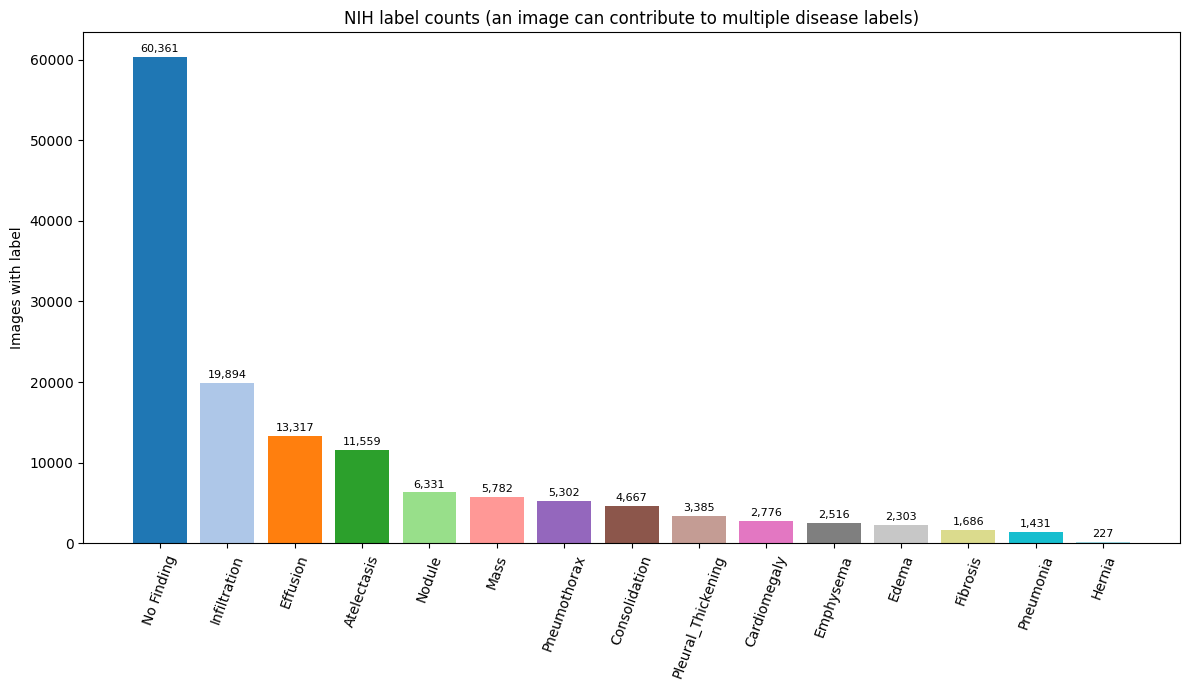

In [22]:
import numpy as np
import matplotlib.pyplot as plt
all_labels_flat = all_xray_df["Finding Labels"].str.split("|").explode()
individual_label_counts = all_labels_flat.value_counts()
fig, ax = plt.subplots(figsize=(12, 7))
colors = plt.cm.tab20(np.linspace(0, 1, len(individual_label_counts)))
bars = ax.bar(individual_label_counts.index, individual_label_counts.values, color=colors)
ax.bar_label(bars, labels=[f"{v:,}" for v in individual_label_counts.values], padding=2, fontsize=8)
ax.set_title("NIH label counts (an image can contribute to multiple disease labels)")
ax.set_ylabel("Images with label")
ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

## 4. Metadata, multi-hot target และ patient-disjoint split
สร้าง 14 target columns ตาม `DISEASE_LABELS`; ภาพหลายโรคมีหลายค่าเป็น 1
split ใช้ Patient ID: ผู้ป่วยคนเดียวกันจะอยู่ใน split เดียวเท่านั้น
stratification ของ pipeline คงสัดส่วนผู้ป่วยที่มี/ไม่มี label ใด ๆ; ต้องตรวจ positive support ของแต่ละโรคในตาราง
ยืนยันว่า archive และ official test list ครบก่อน train แบบ full

In [23]:
from src.engine import save_json
from PIL import Image
import pandas as pd
df, audit = read_multilabel_metadata(DATA_ROOT, allow_partial=ALLOW_PARTIAL)
splits = make_multilabel_splits(df, DATA_ROOT, mode=SPLIT_MODE,
                                seed=SPLIT_SEED, max_patients=MAX_PATIENTS)
split_hash, summary = save_multilabel_splits(splits, OUT/"splits")
save_json(dict(audit=audit, summary=summary, split_hash=split_hash,
               protocol=SPLIT_MODE, profile=PROFILE, max_patients=MAX_PATIENTS,
               labels=list(DISEASE_LABELS), dataset_handle=KAGGLE_HANDLE,
               resolved_dataset_path=str(DATA_ROOT)), OUT/"data_audit.json")
display(pd.DataFrame({name: {label: info["positive_images"]
                                  for label, info in part["labels"].items()}
                      for name, part in summary.items()}))
for split_name, frame in splits.items():
    for path in frame.path:
        with Image.open(path) as im:
            im.verify()
print("Patient/image overlap checks passed; split hash:", split_hash)

,train,val,test
Atelectasis,6636,1644,3279
Cardiomegaly,1367,340,1069
Consolidation,2221,631,1815
Edema,1084,294,925
Effusion,6904,1755,4658
Emphysema,1137,286,1093
Fibrosis,973,278,435
Hernia,114,27,86
Infiltration,10843,2939,6112
Mass,3160,874,1748


Patient/image overlap checks passed; split hash: 657fc2723302bfac6732319a00f50c7e16a00496630b191fdc75beee5ea171b9


## 5. Cache ภาพลง local disk และตรวจภาพ
ย่อแบบ pad + resize เป็น 224×224 **ครั้งเดียว** ก่อน augmentation แล้วบันทึก PNG RGB แบบไม่สูญเสียเพิ่ม
ลดการเปิดและย่อ PNG ต้นฉบับขนาดใหญ่ทุก epoch; ไม่ cache ภาพที่สุ่มหมุน/เลื่อนแล้ว
ชื่อ cache อิง path, ขนาดไฟล์, เวลาแก้ไขและรุ่น preprocessing; ใช้ต่อได้ใน runtime เดิม
เปลี่ยนข้อมูลต้นฉบับให้สร้าง cache ใหม่ (ระบบนี้ไม่ใช้ content hash ของภาพทุกไฟล์)
ขั้นตอนแรกยังใช้เวลา แต่ progress bar แสดงความคืบหน้า
ใช้ 4 workers + pinned memory; ปิด persistent workers เพื่อให้ resume สุ่ม augmentation ต่อได้ที่ขอบ epoch
Batch 64 เป็นค่าเริ่มต้นสำหรับ L4 ที่ 224 px; ถ้า OOM ให้เริ่ม RUN_NAME ใหม่ด้วย batch 32
GPU RAM ไม่จำเป็นต้องเต็ม และต้องดู img/s ร่วมด้วย

Cache resized images:   0%|          | 0/112120 [00:00<?, ?it/s]

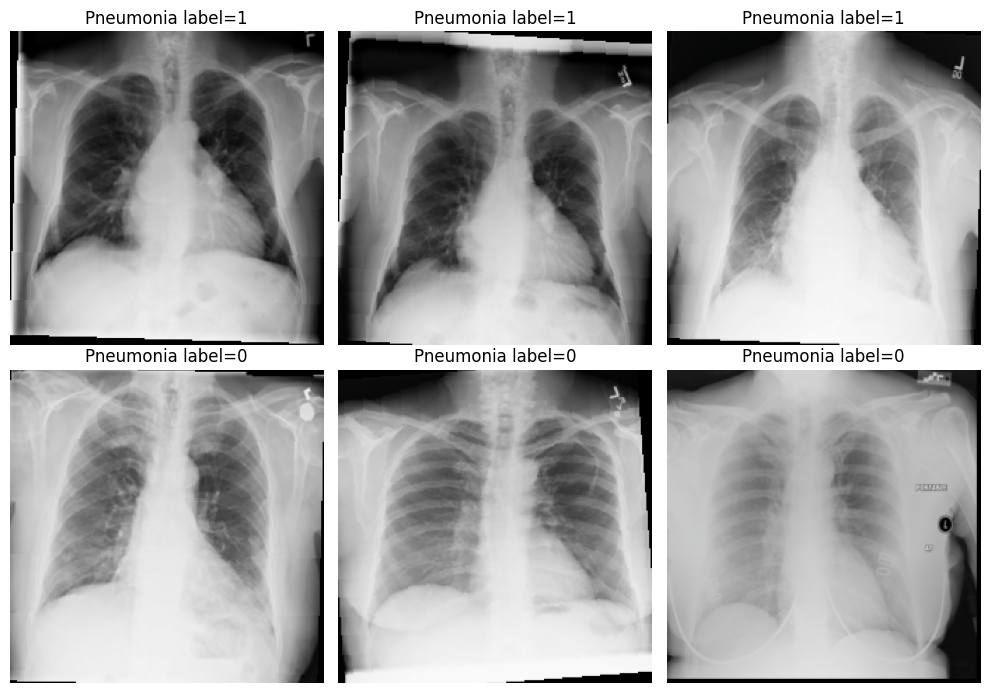

In [24]:
from src.data import prepare_image_cache
CACHE_IMAGES = True
CACHE_ROOT = Path("/content/nih_cache") if Path("/content").exists() else Path("data/nih_cache")
if CACHE_IMAGES:
    free_gib = shutil.disk_usage("/content" if Path("/content").exists() else ".").free/2**30
    if free_gib < 12:
        raise RuntimeError("Keep at least 12 GiB free for cache/checkpoints or set CACHE_IMAGES=False")
    combined = pd.concat(list(splits.values()), ignore_index=True)
    cached_frame = prepare_image_cache(combined, CACHE_ROOT, CFG.image_size, workers=4)
    paths = cached_frame.set_index("Image Index").path
    splits = {key: frame.assign(path=frame["Image Index"].map(paths)) for key, frame in splits.items()}
    save_json(dict(cache_root=str(CACHE_ROOT), size=CFG.image_size,
                   transform="RGB pad+resize v1; random affine remains online"), OUT/"cache_info.json")

import matplotlib.pyplot as plt
import numpy as np
from src.data import ChestDataset
sample = splits["train"].groupby("target", group_keys=False).head(3)
dataset = ChestDataset(sample, train=True, size=CFG.image_size)
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for i, ax in enumerate(axes.flat):
    if i >= len(dataset):
        ax.axis("off"); continue
    x, y = dataset[i]
    image = x.permute(1,2,0).numpy() * [.229,.224,.225] + [.485,.456,.406]
    ax.imshow(np.clip(image, 0, 1)); ax.set_title(f"Pneumonia label={int(y.item())}"); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Train 14 sigmoid outputs
ใช้ `BCEWithLogitsLoss` สำหรับ 14 binary decisions พร้อมกัน ไม่ใช้ softmax เพราะ label ไม่ได้แข่งกันแบบเลือก class เดียว
per-label positive weight = train negatives / positives; clip ไม่เกิน `POS_WEIGHT_CAP`
รายงาน macro AP (ตัวชี้วัดหลัก), micro AP และ AP/AUROC ต่อโรค; ไม่ใช้ accuracy รวมเป็น metric หลัก
threshold แต่ละโรคเลือกจาก validation ให้ recall ถึง `TARGET_RECALL` ตามแผน
ถ้าโรคหายากมี validation positives น้อย ผล AP/threshold จะไม่แน่นอน ให้รายงาน support ด้วย

In [28]:
validation_rows = []
for model_name in MODEL_NAMES:
    # CFG is a SimpleNamespace, convert it to the expected MultiLabelConfig dataclass
    dataclass_cfg = MultiLabelConfig(**vars(CFG))
    model, validation, history = train_multilabel_model(
        model_name, splits, dataclass_cfg, split_hash, OUT/"trials",
        pos_weight_cap=POS_WEIGHT_CAP, target_recall=TARGET_RECALL, resume=RESUME)
    validation_rows.append({"model": model_name, **validation})
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
validation_table = pd.DataFrame(validation_rows).sort_values("macro_ap", ascending=False)
validation_table.to_json(OUT/"validation_comparison.json", orient="records", indent=2)
display(validation_table[["model", "macro_ap", "micro_ap", "macro_auroc"]])
display(pd.DataFrame({row["model"]: row["per_class"] for row in validation_rows}).T)

resnet18 epoch=1 stage=head train=0.7134 val_macro_AP=0.0868 val_micro_AP=0.1675
resnet18 epoch=2 stage=head train=0.6738 val_macro_AP=0.0973 val_micro_AP=0.1814
resnet18 epoch=3 stage=finetune train=0.6305 val_macro_AP=0.1266 val_micro_AP=0.2242
resnet18 epoch=4 stage=finetune train=0.6038 val_macro_AP=0.1372 val_micro_AP=0.2270


KeyboardInterrupt: 

## 7. เลือก backbone จาก validation เท่านั้น
เลือกจาก macro AP เฉลี่ยเท่ากันทั้ง 14 โรค; ดู AP และจำนวน positive รายโรคประกอบ
threshold เป็นรายโรคและเลือกจาก validation ตาม `TARGET_RECALL`
อย่าเปิด test เพื่อปรับโมเดล, loss weight, threshold หรือ class list

In [ ]:
from src.engine import save_json
winner = validation_table.iloc[0]["model"]
selected = next(row for row in validation_rows if row["model"] == winner)
selection = {"selected_model": winner, "split_hash": split_hash,
             "selection_metric": "validation macro AP over 14 labels",
             "labels": list(DISEASE_LABELS),
             "thresholds": {label: selected["per_class"][label]["threshold"]
                            for label in DISEASE_LABELS},
             "validation_macro_ap": selected["macro_ap"]}
save_json(selection, OUT/"locked_selection.json")
save_json(dict(training_code_commit=CODE_SHA), OUT/"code_version.json")
print("Selected model:", winner)
print("Checkpoint:", OUT/"trials"/winner/"best.pt")

Selected experiment: resnet18_pw10
Checkpoint: /content/drive/MyDrive/ChestXrayProject/nih_full_resnet50_v3/resnet18_pw10_seed42/resnet18/best.pt
Validation summary: /content/drive/MyDrive/ChestXrayProject/nih_full_resnet50_v3/validation_comparison.csv


## 8. Final test — เปิดหลัง freeze เท่านั้น
`RUN_FINAL_TEST` ตั้งเป็น False จนกว่าจะยุติการพัฒนาและล็อก selection/thresholds
test ใช้รายงานครั้งสุดท้าย ไม่ใช้เพื่อเลือก backbone หรือแก้ threshold

In [ ]:
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    import json
    test_dir = OUT/"final_test"
    if (test_dir/"STARTED.json").exists():
        raise RuntimeError("Test was already opened; do not tune on it")
    test_dir.mkdir(exist_ok=True)
    save_json(dict(selection=selection, code_commit=CODE_SHA), test_dir/"STARTED.json")
    loaders, _ = make_multilabel_loaders(splits, CFG.batch_size, SPLIT_SEED,
                                         CFG.image_size, CFG.num_workers)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, _ = load_multilabel_model(OUT/"trials"/winner/"best.pt", device)
    y_test, scores_test = predict_multilabel(model, loaders["test"], device)
    thresholds = [selection["thresholds"][label] for label in DISEASE_LABELS]
    test_metrics = multilabel_metrics(y_test, scores_test, thresholds)
    save_json(test_metrics, test_dir/"test_metrics.json")
    pred = splits["test"][["Image Index", "patient_id"]].reset_index(drop=True).copy()
    for i, label in enumerate(DISEASE_LABELS):
        pred[f"true_{label}"] = y_test[:, i].astype(int)
        pred[f"score_{label}"] = scores_test[:, i]
        pred[f"pred_{label}"] = (scores_test[:, i] >= thresholds[i]).astype(int)
    pred.to_csv(test_dir/"test_predictions.csv", index=False)
    display(pd.DataFrame(test_metrics["per_class"]).T)
else:
    print("Final test is still unopened.")

Training/validation completed. Final test is still unopened.


## 9. ทดลองทำนายภาพเดียว
รายงานทุกโรคที่ score ผ่าน threshold ของโรคนั้น และแสดง Grad-CAM สำหรับ score สูงสุด
score จาก weighted BCE ยังไม่ใช่ความน่าจะเป็นทางคลินิกที่ผ่าน calibration

In [ ]:
IMAGE_PATH = ""  # Set an image path; the file is not uploaded.
if IMAGE_PATH:
    from PIL import Image
    import numpy as np
    import matplotlib.pyplot as plt
    from src.data import transforms
    from src.explain import grad_cam
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, _ = load_multilabel_model(OUT/"trials"/winner/"best.pt", device)
    with Image.open(IMAGE_PATH) as image:
        x = transforms(size=CFG.image_size)(image.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        scores = model(x).sigmoid()[0].cpu().numpy()
    thresholds = np.array([selection["thresholds"][label] for label in DISEASE_LABELS])
    predicted = [label for label, score, threshold in zip(DISEASE_LABELS, scores, thresholds)
                 if score >= threshold]
    print({"predicted_labels": predicted or ["No Finding"],
           "scores": dict(zip(DISEASE_LABELS, scores.tolist())),
           "note": "educational output; not a diagnosis"})
    top_index = int(scores.argmax())
    cam = grad_cam(model, x)[0]
    rgb = x[0].detach().cpu().permute(1, 2, 0).numpy() * [.229, .224, .225] + [.485, .456, .406]
    plt.imshow(np.clip(rgb, 0, 1)); plt.imshow(cam, cmap="jet", alpha=.4)
    plt.axis("off"); plt.title(f"Grad-CAM: {DISEASE_LABELS[top_index]} (not a lesion annotation)")
    plt.show()

## 10. ผลลัพธ์และการแก้ตัวแปร
`OUT/data_audit.json` และ `OUT/splits/*.csv` เก็บ support ของทุก label และ patient IDs
`OUT/trials/<model>/validation.json` เก็บ macro/micro AP, metrics และ threshold รายโรค
`OUT/trials/<model>/val_predictions.csv` เก็บ target/score รายโรค
`OUT/locked_selection.json` บันทึก backbone และ threshold ที่เลือกก่อนเปิด test
`OUT/final_test/test_metrics.json` และ `test_predictions.csv` จะเกิดเมื่อเปิด final test เท่านั้น
เปลี่ยน `PROFILE`, `MODEL_NAMES`, `POS_WEIGHT_CAP`, `TARGET_RECALL` หรือ `CFG` ต้องใช้ `RUN_NAME` ใหม่
runtime notebook รุ่น binary ที่กำลังดาวน์โหลดไม่ถูกแก้หรือ reset จากไฟล์ใหม่นี้
โค้ด multi-label helper อยู่ในไฟล์ notebook นี้; ไม่ต้อง push หรืออัปโหลดไฟล์ `.py` เพิ่ม
ผลนี้เป็น internal NIH evaluation; อย่าอ้างเป็น external/clinical validation

In [ ]:
(OUT / "environment_freeze.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")
print("Artifacts saved in:", OUT)
print("Use the result files to complete the report; do not report smoke-test scores as real performance.")

Artifacts saved in: /content/drive/MyDrive/ChestXrayProject/nih_full_resnet50_v3
Use the result files to complete the report; do not report smoke-test scores as real performance.
